# Backlog v3 — affordable judge use and frozen classifier verification

Read `docs/SPAN_003_PROTOCOL.md` and `docs/SPAN_003_RESULTS.md` for the contract,
measured outcomes and remaining work. Cached comparisons use the same2,048
inspected development rows; they are not full-development or official scores.
Confirmation is unused. Failed runtime/numerical gates remain visible.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists():REPO=REPO.parent
assert (REPO/'GOAL.md').exists()
RESULTS=REPO/'results/span_003'
FIGURES=Path.home()/'database/llm_classification_finetuning/runs/span_003/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def read(name):return json.loads((RESULTS/name).read_text())
def save(fig,name):
    for extension in ['png','svg']:
        fig.savefig(FIGURES/(name+'.'+extension),bbox_inches='tight',dpi=160)
    plt.show()
registry=json.loads((REPO/'backlog/hypotheses.json').read_text())
v3=next(v for v in registry['versions'] if v['number']==3)
records={item['id']:item for item in registry['items']}
display(pd.DataFrame([{'task':key,'title':records[key]['title'],'status':records[key]['status']}
                      for key in v3['focus_ids']]))
plan=read('span_plan.json')
print('v3 state:',v3['state'],'original start:',plan['started_at'],'deadline:',plan['deadline'])
print('Effective GPU cap:',plan['gpu_session_seconds_cap']/3600,'elapsed two-T4 session-hours')


,task,title,status
0,E03,Verify the continued classifier export offline...,running
1,H39,Budgeted strong-judge cascade,done
2,E02,Package an offline native CUDA runtime and ver...,done
3,H43,Blend conditional winner preferences while pre...,done


v3 state: active original start: 2026-11-04T07:42:17+00:00 deadline: 2026-11-06T07:42:17+00:00
Effective GPU cap: 8.354526666666667 elapsed two-T4 session-hours


## H39/H43: matched nested cached comparisons

Five outer prompt-grouped folds evaluate each candidate; three inner folds select
recipes, with component calibration, weights and gates fitted without evaluation
groups. Intervals use2,000 paired group-bootstrap draws conditional on OOF
predictions. Earlier development inspection and multiple comparisons remain limits.


,system,rows,log_loss,accuracy,tie_loss,tie_recall,tie_auc
0,classifier,2048,0.959997,0.520020,1.044415,0.381102,0.687617
1,judge,2048,0.986748,0.507812,1.101243,0.349606,0.645448
2,vector,2048,0.941681,0.563477,1.044273,0.414173,0.698961
3,conditional,2048,0.945236,0.548340,1.044415,0.409449,0.687617
4,vector_tie,2048,0.931579,0.563965,1.048087,0.431496,0.697991
5,entropy_10,2048,0.957587,0.533691,1.045299,0.393701,0.687196
6,entropy_20,2048,0.955138,0.534180,1.042197,0.398425,0.690197
7,random_10,2048,0.958736,0.525879,1.044982,0.387402,0.687699
8,random_20,2048,0.956761,0.527832,1.041526,0.388976,0.690049
9,selected_blend,2048,0.931579,0.563965,1.048087,0.431496,0.697991


,fold,selected_blend,selected_entropy,selected_random
0,0,vector_tie,entropy_20,random_20
1,1,vector_tie,entropy_20,random_20
2,2,vector_tie,entropy_20,random_20
3,3,vector_tie,entropy_20,random_20
4,4,vector_tie,entropy_20,random_20


,rows,fraction,human_class_counts
entropy_10,207,0.101074,"[65, 67, 75]"
entropy_20,408,0.199219,"[135, 131, 142]"
random_10,208,0.101562,"[71, 64, 73]"
random_20,408,0.199219,"[136, 131, 141]"
selected_entropy,408,0.199219,"[135, 131, 142]"
selected_random,408,0.199219,"[136, 131, 141]"


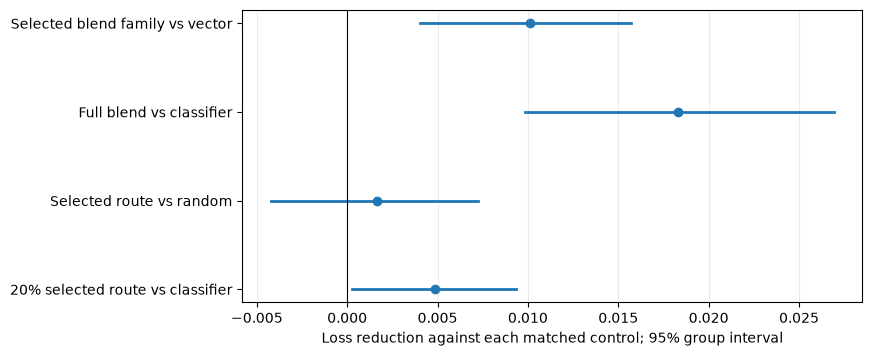

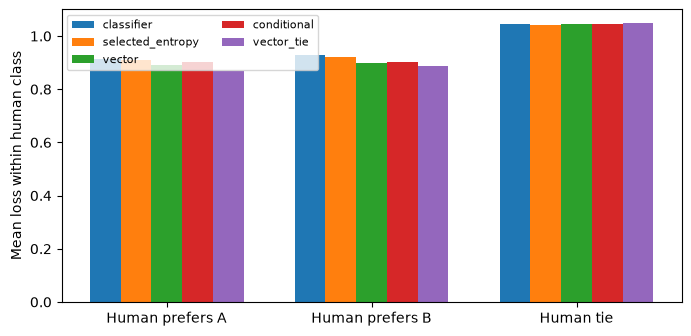

,system,binary_tie_log_loss,conditional_winner_contribution,sum_multiclass_loss,decisive_rows,tie_rows,conditional_winner_log_loss,conditional_winner_accuracy,note
0,classifier,0.562899,0.397098,0.959997,1413,635,0.575553,0.687898,Decomposition uses observed votes for descript...
1,selected_entropy,0.561493,0.393645,0.955138,1413,635,0.570549,0.704883,Decomposition uses observed votes for descript...
2,vector,0.560619,0.381062,0.941681,1413,635,0.552311,0.725407,Decomposition uses observed votes for descript...
3,conditional,0.562899,0.382337,0.945236,1413,635,0.554159,0.716914,Decomposition uses observed votes for descript...
4,vector_tie,0.557648,0.373931,0.931579,1413,635,0.541974,0.725407,Decomposition uses observed votes for descript...


Binary tie BCE differs from loss on human-tie rows; conditional winner accuracy is not3-class accuracy.


,baseline,rows,log_loss,accuracy,macro_f1,brier,class_counts,class_loss,class_recall,tie_precision,mean_predictive_entropy,mean_class_probability,predicted_class_fraction,tie_auc,confusion_matrix
0,training_prior,2048,1.097555,0.338379,0.168552,0.665976,"[693, 720, 635]","[1.052482, 1.073191, 1.174369]","[1.0, 0.0, 0.0]",0.0,1.097227e+00,"[0.34907, 0.341916, 0.309014]","[1.0, 0.0, 0.0]",0.5,"[[693, 0, 0], [720, 0, 0], [635, 0, 0]]"
1,majority_clipped_1e-12,2048,18.281266,0.338379,0.168552,1.323242,"[693, 720, 635]","[0.0, 27.631021, 27.631021]","[1.0, 0.0, 0.0]",0.0,5.726222e-11,"[1.0, 0.0, 0.0]","[1.0, 0.0, 0.0]",0.5,"[[693, 0, 0], [720, 0, 0], [635, 0, 0]]"
2,uniform,2048,1.098612,0.338379,0.168552,0.666667,"[693, 720, 635]","[1.098612, 1.098612, 1.098612]","[1.0, 0.0, 0.0]",0.0,1.098612e+00,"[0.333333, 0.333333, 0.333333]","[1.0, 0.0, 0.0]",0.5,"[[693, 0, 0], [720, 0, 0], [635, 0, 0]]"


Exact hard-majority loss is infinite on errors. Finite diagnostic uses1e-12 clipping; deterministic argmax ties choose A.
Latest classifier raw-order behavior: {'decision_disagreement': 0.263671875, 'mean_probability_l1': 0.22392356990630194, 'second_position_advantage': -0.012215710294192012}
Unchanged packing retention: {'rows': 2048, 'any_field_cut_fraction': 0.19970703125, 'prompt_cut_fraction': 0.0732421875, 'answer_cut_fraction': 0.16650390625, 'mean_row_content_retained_fraction': 0.9339165876151628, 'corpus_content_retained_fraction': 0.8000175828197268, 'raw_content_tokens': 1399093, 'retained_content_tokens': 1119299}
Judge order coverage: Judge is single-order; no native both-order invariance measured.
Shared CPU analysis seconds: 9.085397250950336


In [2]:
cached=read('cached_results.json')
display(pd.DataFrame([{'system':name,'rows':m['rows'],'log_loss':m['log_loss'],
                      'accuracy':m['accuracy'],'tie_loss':m['class_loss'][2],
                      'tie_recall':m['class_recall'][2],'tie_auc':m['tie_auc']}
                     for name,m in cached['models'].items()]))
display(pd.DataFrame([{'fold':fold['fold'],**fold['selected']} for fold in cached['folds']]))
display(pd.DataFrame(cached['routing']).T)
contrasts=[('20% selected route vs classifier','selected_entropy_vs_classifier'),
           ('Selected route vs random','selected_entropy_vs_selected_random'),
           ('Full blend vs classifier','vector_vs_classifier'),
           ('Selected blend family vs vector','selected_blend_vs_vector')]
fig,ax=plt.subplots(figsize=(8,3.8))
for index,(label,key) in enumerate(contrasts):
    value=cached['contrasts'][key];lo,hi=value['interval_95']
    ax.plot([lo,hi],[index,index],color='C0',linewidth=2)
    ax.scatter(value['gain'],index,color='C0')
ax.set_yticks(range(len(contrasts)),[label for label,_ in contrasts])
ax.axvline(0,color='black',linewidth=.8);ax.grid(axis='x',alpha=.25)
ax.set_xlabel('Loss reduction against each matched control; 95% group interval')
save(fig,'cached_gains')
names=['classifier','selected_entropy','vector','conditional','vector_tie']
fig,ax=plt.subplots(figsize=(8,3.8));x=np.arange(3);width=.15
for index,name in enumerate(names):
    ax.bar(x+(index-2)*width,cached['models'][name]['class_loss'],width,label=name)
ax.set_xticks(x,['Human prefers A','Human prefers B','Human tie'])
ax.set_ylabel('Mean loss within human class');ax.legend(fontsize=8,ncol=2)
save(fig,'class_losses')
display(pd.DataFrame([{'system':name,**cached['models'][name]['loss_decomposition']} for name in names]))
print('Binary tie BCE differs from loss on human-tie rows; conditional winner accuracy is not3-class accuracy.')
display(pd.DataFrame([{'baseline':name,**metric} for name,metric in cached['constant_controls'].items()]))
print(cached['hard_majority_note'])
print('Latest classifier raw-order behavior:',cached['classifier_raw_order'])
print('Unchanged packing retention:',cached['retention'])
print('Judge order coverage:',cached['native_order_limit'])
print('Shared CPU analysis seconds:',cached['cpu_elapsed_seconds'])


## E03: frozen classifier export and actual official receipt

The64-row Internet-disabled reload and both visible CSVs are independently
checked. Visible3-row predictions do not establish a leaderboard score.
The frozen temperature/adapter are unchanged. Submission remains pending until
the exact accepted receipt is terminal with a real score.


In [3]:
verification=read('classifier_verification.json')
display(pd.DataFrame(verification['identity']['identity']).T)
display(pd.DataFrame(verification['independently_validated_previews']).T)
print('Frozen temperature:',verification['identity']['temperature'])
print('Runtime software:',verification['identity']['software'])
print('Rank0 peak allocated GPU bytes:',verification['identity']['peak_gpu_bytes_rank0'])
if (RESULTS/'receipt.json').exists():print('Official receipt:',read('receipt.json'))
if (RESULTS/'official_result.json').exists():
    print('Observed official result:',read('official_result.json'))
else:print('New official score not yet available; recorded best before span was0.97025.')
if (RESULTS/'official_accounting.json').exists():
    print('Measured charges and conservative hidden bound:',read('official_accounting.json'))


,mean,maximum
original,0.000294,0.003542
aligned_swap,0.000261,0.002268
average,0.000212,0.002180
calibrated,0.000221,0.002287


,csv_sha256,rows,valid,session,kernel,version
classifier_smoke,b7e5bc4fe7b7e37d9c266d47d203ea07f04b717a0e4d73...,3,True,"{'seconds': 184.8633496761322, 'smoke_passed':...",/code/arseniytrushin/llm-preference-span-003-c...,1
classifier_predict,b7e5bc4fe7b7e37d9c266d47d203ea07f04b717a0e4d73...,3,True,"{'seconds': 109.62726378440857, 'prediction_co...",/code/arseniytrushin/llm-preference-span-003-c...,1


Frozen temperature: 0.9441963863130951
Runtime software: {'torch': '2.11.0+cu130', 'transformers': '5.22.1', 'peft': '0.21.2', 'accelerate': '1.15.0', 'bitsandbytes': '0.50.2'}
Rank0 peak allocated GPU bytes: 4234590208
Official receipt: {'ref': 57979825, 'message': ''}
Observed official result: {'ref': 57979825, 'status': 'SubmissionStatus.PENDING', 'public_score': '', 'private_score': '', 'date': '2026-11-04 09:31:36.027000', 'description': 'Span003 frozen H03 step1438; T0.9441963863; no refit', 'url': '/code/arseniytrushin/llm-preference-span-003-classifier-predict?scriptVersionId=365549578'}


## E02/H39: native hardware works; numerical and deployment gates fail

The first library-size heuristic was incorrect; the corrected artifact is verified
by ELF/header/runtime checksum, licenses, ldd and real two-T4 inference. The
unchanged raw-cache identity limit still fails. Preserve that failure and stop
optional new-row expansion. Hardware success is not cache-recipe compatibility.


Native gate: {'rows': 64, 'mean_probability_difference': 0.02089541270889921, 'max_probability_difference': 0.18872561257683373, 'mean_limit': 0.01, 'max_limit': 0.1, 'identity_passed': False, 'seconds_per_row': 1.2114766367656262, 'scoring_seconds': 77.53450475300008, 'setup_seconds_before_profile': 17.430931568145752, 'sampled_gpu_used_peak_mib': [9543, 8833], 'memory_samples': 640, 'memory_note': 'Sampled total device memory used, including driver/runtime; not allocator peak memory.', 'native_both_devices_verified': True, 'session_seconds': 358.2742474079132}
Decision: Stop at the declared numerical/runtime gates. No route passes quality, current runtime and cache-identity gates together; do not score the optional1024 rows or reuse incompatible calibrators.
Numerical cause: Not isolated; no claim that packaging, batching or a particular kernel caused the drift.


,view,log_loss,accuracy
0,old_raw,1.405440,0.468750
1,current_raw,1.441182,0.484375
2,old_fixed_calibration,0.972024,0.484375
3,current_fixed_calibration,0.980742,0.468750


Frozen-calibration drift diagnostic: {'gain': -0.008717302792099096, 'interval_95': [-0.023044969915802915, 0.004657565777953408], 'groups': 64, 'rows': 64, 'replicates': 2000}
Frozen 2048-row v3 fitting recipe; includes these64 known rows, not independent validation.


,route,projected_seconds_before_additional_model_loading,runtime_guard_passed,cached_quality_gate_passed
0,entropy_10,22410.374984,True,False
1,entropy_20,26044.804894,False,True


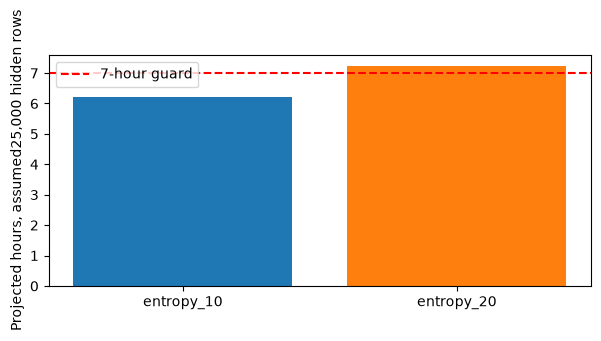

Projection includes20% inference margin +600s; excludes additional model loading.
Device-used memory peaks MiB: [9543, 8833]
Sampled total device memory used, including driver/runtime; not allocator peak memory.
Native charges: 39.515 373.40499999999884 seconds


In [4]:
native=read('native_profile_results.json')
print('Native gate:',native['gate'])
print('Decision:',native['decision'])
print('Numerical cause:',native['numerical_cause'])
diagnostic=native['loss_diagnostic']
display(pd.DataFrame([{'view':name,'log_loss':diagnostic[name]['log_loss'],
                      'accuracy':diagnostic[name]['accuracy']}
                     for name in ['old_raw','current_raw','old_fixed_calibration','current_fixed_calibration']]))
print('Frozen-calibration drift diagnostic:',diagnostic['fixed_calibration_loss_effect'])
print(diagnostic['calibrator_source'])
display(pd.DataFrame([{'route':name,**{k:v for k,v in value.items() if k!='gain'}}
                     for name,value in native['routes'].items()]))
fig,ax=plt.subplots(figsize=(7,3))
labels=list(native['routes'])
hours=[native['routes'][name]['projected_seconds_before_additional_model_loading']/3600 for name in labels]
ax.bar(labels,hours,color=['C0','C1']);ax.axhline(7,color='red',linestyle='--',label='7-hour guard')
ax.set_ylabel('Projected hours, assumed25,000 hidden rows');ax.legend()
save(fig,'cascade_runtime_guard')
print('Projection includes20% inference margin +600s; excludes additional model loading.')
print('Device-used memory peaks MiB:',native['gate']['sampled_gpu_used_peak_mib'])
print(native['gate']['memory_note'])
print('Native charges:',native['original_failure_charge_seconds'],native['retry_charge_seconds'],'seconds')


## Resources, uncertainty and versioned handoff

All failures and previews count. The official hidden rerun may not expose its GPU
cost in weekly quota; report measured charges and a conservative execution bound
separately. The goal finishes only after reports, terminal audits, notebook,
sealed-v3/v4 handoff and publication, stopping before v4 execution.


In [5]:
print('Original resource plan:',plan)
print('Charged seconds at native completion:',native['span_charged_seconds_so_far'])
if (RESULTS/'local_audit.json').exists():
    audit=read('local_audit.json')
    print('Independent local verification:',{key:audit.get(key) for key in
          ['passed','cached_rows','cached_groups','reconstructed_fold_predictions',
           'independently_recomputed_models','independently_recomputed_contrasts']})
if (RESULTS/'decisions.json').exists():
    decisions=read('decisions.json')
    display(pd.DataFrame([{'task':name,'experiment_complete':value['experiment_complete'],
                          'decision':value['reason']} for name,value in decisions['tasks'].items()]))
    print('Best recorded official:',decisions['best_recorded_official_now'])
for filename in ['submission_intent.json','terminal_audit.json','closure_audit.json']:
    if (RESULTS/filename).exists():print(filename,read(filename))
display(pd.DataFrame([{'version':v['number'],'state':v['state'],'tasks':len(v['item_ids']),
                      'focus':v['focus_ids']} for v in registry['versions']]))
print('Figures:',FIGURES)


Original resource plan: {'span': 3, 'started_at': '2026-11-04T07:42:17+00:00', 'deadline': '2026-11-06T07:42:17+00:00', 'gpu_session_seconds_cap': 30076.296000000002, 'quota_used_at_start': 77923.704, 'initial_quota_refresh_time': '2026-11-07 00:00:00', 'per_job_seconds_cap': 25200, 'focus': ['E03', 'H39', 'E02', 'H43'], 'seed': 20261120, 'confirmation_used': False}
Charged seconds at native completion: 738.2970000000059
Independent local verification: {'passed': True, 'cached_rows': 2048, 'cached_groups': 1953, 'reconstructed_fold_predictions': 60, 'independently_recomputed_models': 12, 'independently_recomputed_contrasts': 16}


,task,experiment_complete,decision
0,H43,True,Conditional tie preservation loses to the cali...
1,H39,True,20% route misses the current projected runtime...
2,E02,True,Native CUDA and actual two-device inference wo...
3,E03,False,One frozen classifier submitted; monitor its e...


Best recorded official: 0.97025
submission_intent.json {'created_at': '2026-11-04T09:31:32.509412+00:00', 'kernel': 'arseniytrushin/llm-preference-span-003-classifier-predict', 'version': 1, 'notebook_sha256': '73457410843da9f15417e4bbc4b85969eae4860b1fdcf189be12a6ff5fd9e0e4', 'manifest_sha256': '2091f699df6f3b17a79f2d23f22827013598748ffe8599f9cafc61b0052fd56c', 'adapter_sha256': 'ca8be9cfd98309fdc8406bf740b13ed3ee413f3820ec6bcbbf7f3f4059f4b15b', 'quota_before': {'used_seconds': 78662.001, 'reserved_seconds': 0.0, 'allowed_seconds': 108000.0, 'refresh_time': '2026-11-07 00:00:00', 'paid_scaling': False}, 'observed_span_charged_before': 738.2970000000059, 'hidden_execution_ceiling_seconds': 21600, 'conservative_span_seconds_bound': 22338.297000000006, 'span_cap_seconds': 30076.296000000002, 'projection_rows_assumption': 25000, 'projected_seconds_including_measured_setup': 18879.006430715745, 'all_owned_observed_terminal': True, 'owned_notebook_count': 49, 'unobserved_old_notebooks': [{'

,version,state,tasks,focus
0,1,closed,41,"[E00, H01, H09, H04, H11]"
1,2,closed,39,"[H40, E01, H03, H37, H42]"
2,3,active,37,"[E03, H39, E02, H43]"
3,4,draft,2,[]


Figures: /home/tarstars/database/llm_classification_finetuning/runs/span_003/figures
